[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/multigeom/multigeom-tutorials/blob/steeve-g/notebooks/21_posterior_samples.ipynb)

# Images generated from neural responses: samples of p(x | r)

* **Author**: laquitainesteeve@gmail.com

* **Goal**: Show what the responses of a population determine about an image. For the frog and 3 test images: (1) simulate one noisy response r of a retina mosaic (W3 cell 176-exp7) and of V1 and V4 (the inception models fitted to Papale's recordings); (2) run the backward diffusion process conditioned on r, which generates samples of p(x | r), images consistent with the response; (3) along the way, show the estimate $\hat x(x_t, r)$ of the image at each step, what is recovered at each noise scale.

* **Requirements**: TinyImageNet, the checkpoints of V1, V4 and the retina (downloaded below), a GPU, `multigeom` from the `g-per-scale` branch and `openretina` from the private repository `open-retina-multigeom`.

* **Time**: a few minutes on a GPU.

## 1. Setup

### 1.1. Install package

Install the version of `multigeom` this notebook needs, the `g-per-scale` branch on GitHub, and, on Google Colab, `openretina` from the private repository `open-retina-multigeom` (with a GitHub token stored in Colab's secrets as `GH_TOKEN`). Elsewhere, `multigeom` is installed only if the installed one lacks its functions, and `openretina` as the README of `tests/fixtures/retina/` says.

In [1]:
%%time

# the multigeom this notebook needs: the g-per-scale branch on GitHub, until it is
# released (without its dependencies: Colab already has torch, numpy, scipy and
# matplotlib, and reinstalling torch is slow and can break the GPU runtime)
import os
import sys

BRANCH = "git+https://github.com/multigeom/multigeom.git@g-per-scale"

# on Google Colab: install the latest commit of that branch (forced: pip skips a
# branch it installed before, even if the branch has changed since), and the
# diffusion models' library
if "google.colab" in sys.modules:
    %pip install -q --no-deps --force-reinstall {BRANCH}
    %pip install -q "diffusers>=0.30,<0.38"

    # an older multigeom imported earlier in this session stays in memory: restart
    # the session so that the next cells import the new one (then run them from the
    # next cell on)
    # open-retina with Baptiste Lorenzi's retina models: the private repository
    # open-retina-multigeom, with a GitHub token in Colab's secrets (GH_TOKEN)
    from google.colab import userdata

    TOKEN = userdata.get("GH_TOKEN")
    RETINA = "github.com/steevelaquitaine/open-retina-multigeom.git"
    %pip install -q --no-deps "git+https://{TOKEN}@{RETINA}"
    DEPENDENCIES = (
        "jaxtyping hydra-core lightning tenacity opencv-python-headless seaborn"
    )
    %pip install -q {DEPENDENCIES} moviepy

    if "multigeom" in sys.modules:
        print("restarting the session to load the new multigeom: run the next cells")
        os.kill(os.getpid(), 9)

# on your own machine: install the latest commit of that branch only if the installed
# multigeom lacks a function this notebook imports (an up-to-date editable install is
# kept; installing replaces it: restart the kernel afterwards)
else:
    import importlib
    import inspect

    NEEDED = {
        "multigeom.config": {"load_config": []},
        "multigeom.datasets": {
            "CANONICAL_TRANSFORM": [],
            "TinyImageNetDataset": ["split", "transform"],
            "download_tinyimagenet": [],
            "load_examples": [],
        },
        "multigeom.diffusion": {"sample_images": ["generator", "keep", "responses"]},
        "multigeom.diffusion.model": {"build_scheduler": []},
        "multigeom.encoders.retina": {
            "load_retina": ["normalizer_cache"],
            "load_retina_images": [],
        },
        "multigeom.pipeline.metric_field": {"load_models": []},
        "multigeom.plotting": {
            "get_trajectory_scales": [],
            "plot_posterior_samples": [],
        },
        "multigeom.utils": {
            "get_device": [],
            "load_intermediate": [],
            "save_intermediate": [],
        },
    }
    missing = []
    for module, functions in NEEDED.items():
        try:
            found = importlib.import_module(module)
        except ImportError:
            missing += [f"{module}.{name}" for name in functions]
            continue
        for name, keywords in functions.items():
            item = getattr(found, name, None)
            if item is None:
                missing.append(f"{module}.{name}")
            elif keywords:
                parameters = inspect.signature(item).parameters
                missing += [f"{name}({k}=)" for k in keywords if k not in parameters]
    if missing:
        %pip install -q --no-deps --force-reinstall {BRANCH}
        print("missing", missing, "- installed multigeom from the branch: restart")

CPU times: user 3.02 s, sys: 80.5 ms, total: 3.1 s
Wall time: 590 ms


### 1.2. Imports and parameters

Work from the repository root, import the packages, and set the parameters: the images, the populations, the samples, the steps shown, and where the results and figures go.

<details><summary>Details</summary>

* `sample_images(..., responses=r)` runs the backward diffusion process (the DDPM sampler the models were trained for) conditioned on the responses r, from pure noise to an image, and keeps the noisy image $x_t$ and the estimate $\hat x(x_t, r)$ (Tweedie's formula) at the steps of `keep`.
* `load_retina_images` prepares image files as open-retina prepares its images (120 x 120, standardised, in the diffusion model's units); V1 and V4 use the 64 x 64 images of the pipeline, in [-1, 1].

</details>

In [2]:
%%time

import os
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from huggingface_hub import snapshot_download

# move to the repository root (the folder containing environment.yml): data/, runs/
# and assets/ are read and written from there
root = Path.cwd().resolve()
while not (root / "environment.yml").exists() and root != root.parent:
    root = root.parent

if (root / "environment.yml").exists():
    os.chdir(root)

print("repo root:", root)

from multigeom.config import load_config
from multigeom.datasets import (
    CANONICAL_TRANSFORM,
    TinyImageNetDataset,
    download_tinyimagenet,
    load_examples,
)
from multigeom.diffusion import sample_images
from multigeom.diffusion.model import build_scheduler
from multigeom.encoders.retina import load_retina, load_retina_images
from multigeom.pipeline.metric_field import load_models
from multigeom.plotting import get_trajectory_scales, plot_posterior_samples
from multigeom.utils import get_device, load_intermediate, save_intermediate

# the parameters of this notebook
PARAMS = {
    # the presented images: the frog, then test images by index
    "frog": "data/tiny-imagenet-200/train/n01644900/images/n01644900_0.JPEG",
    "test_images": [0, 16, 27],
    # the populations: a retina mosaic, and V1 and V4 (the inception models)
    "retina_area": "retina-W3_176-exp7",
    "retina_name": "retina (W3 176-exp7)",
    "encoder": "inception",
    "areas": ["V1", "V4"],
    "frames": "data/tiny-imagenet-200/train",
    "normalizer": "data/02_intermediate/retina/normalizer.pt",
    # the samples of p(x | r) per image (all given the same response), and the seed
    "n_samples": 3,
    "seed": 0,
    # the DDPM steps shown: pure noise (999), one at τ = log t = 3.6, every 0.3 from
    # τ = 3.2 to 0.4 where the image forms (as in notebook 18), τ = 0, −0.6 and −2.1,
    # and the last step (the generated image)
    "keep": [999, 597, 564, 529, 502, 475, 446, 417, 387, 357, 327, 297]
    + [258, 204, 102, 0],
    # where the results are stored (True: recompute and overwrite them), where the
    # figures are saved, their resolution in the file and on screen, and the images
    # whose figures stay in the notebook
    "intermediate_dir": "data/02_intermediate/21_posterior_samples",
    "recompute": False,
    "figure_dir": "assets/figures/posterior_samples",
    "file_dpi": 200,
    "screen_dpi": 100,
    "show": ["frog"],
    # the retina's samples drift in overall brightness (its denoiser keeps the
    # brightness of the noise, notebook 13): its estimates are drawn with their mean
    # removed, each sample on its own gray scale
    "remove_mean": ["retina (W3 176-exp7)"],
}

# the diffusion config (packaged with multigeom): σ of the V1 and V4 responses
diff_cfg = load_config("diffusion")
sigma = float(diff_cfg.conditioning.observation_noise_sigma)

# compute device
device = get_device(None)
print("device:", device)

repo root: /home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials


device: cuda
CPU times: user 955 ms, sys: 137 ms, total: 1.09 s
Wall time: 1.1 s


## 2. Download the models and the datasets

The checkpoints of V1, V4 and the retina are on Hugging Face; TinyImageNet gives the images.

In [3]:
%%time

# the checkpoints (files already in runs/ are kept; the older checkpoints are skipped),
# and TinyImageNet (nothing if already there)
snapshot_download(
    repo_id="steevelaquitaine/multigeom",
    local_dir="runs",
    ignore_patterns=["archive/*"],
)
download_tinyimagenet()

# the stored results of this notebook (and those it reuses), from the dataset
# steevelaquitaine/multigeom-results, if they are published there; otherwise the
# notebook computes them (no download with PARAMS["recompute"])
from huggingface_hub import snapshot_download as download_results

if not PARAMS.get("recompute", False):  # recomputed anyway otherwise
    try:
        download_results(
            repo_id="steevelaquitaine/multigeom-results",
            repo_type="dataset",
            local_dir="data/02_intermediate",
            allow_patterns=[
                f"{folder}/*" for folder in ["21_posterior_samples", "retina"]
            ],
        )
    except Exception as error:  # not published yet, or offline
        print("stored results not downloaded:", type(error).__name__)

Fetching 25 files:   0%|          | 0/25 [00:00<?, ?it/s]

CPU times: user 78.6 ms, sys: 19.4 ms, total: 98 ms
Wall time: 234 ms


PosixPath('/home/steeve/steeve/idv/code/proj_multigeom/multigeom-tutorials/data/tiny-imagenet-200')

## 3. Simulate the responses, and sample p(x | r)

For each population: the presented images in its units, one noisy response r to each (Poisson spike counts for the retina, Gaussian noise of σ = 0.22 for V1 and V4, as the models were trained), then 3 images generated from pure noise given r, keeping $x_t$ and $\hat x(x_t, r)$ at the steps shown. Stored in `data/02_intermediate/21_posterior_samples/results.pt`.

<details><summary>Details</summary>

* The 3 samples of an image share its response, so they differ only by the noise of the sampler: how much they differ shows how much the response leaves open.
* The retina sees 120 x 120 images, standardised together as open-retina does; V1 and V4 see 64 x 64 images. The figures compare the populations side by side, not pixel by pixel.

</details>

In [4]:
%%time


def sample_population(images, encoder, unet, alphas_cumprod, draw_responses):
    """For `images` [n, 1, H, W]: one noisy response to each, then n_samples images
    generated given it, with the steps of PARAMS["keep"]: (images, trajectory keyed by
    τ = log t, with [n, n_samples, 1, H, W] tensors)."""
    generator = torch.Generator(device=device).manual_seed(PARAMS["seed"])
    with torch.no_grad():
        responses = draw_responses(encoder(images.to(device)), generator)
    k = PARAMS["n_samples"]
    _, trajectory = sample_images(
        unet,
        alphas_cumprod,
        (len(images) * k, *images.shape[1:]),
        device,
        generator=generator,
        keep=PARAMS["keep"],
        responses=responses.repeat_interleave(k, dim=0),
    )
    trajectory = {
        step: tuple(x.view(len(images), k, *x.shape[1:]) for x in pair)
        for step, pair in trajectory.items()
    }
    return images.cpu(), get_trajectory_scales(trajectory, alphas_cumprod.cpu())


results_file = Path(PARAMS["intermediate_dir"]) / "results.pt"
examples = load_examples(PARAMS, PARAMS["seed"])
names = list(examples)
if results_file.exists() and not PARAMS["recompute"]:
    results = load_intermediate(results_file)
else:
    results = {}

    # the retina mosaic: the image files prepared as open-retina does, Poisson noise
    test_set = TinyImageNetDataset(split="val", transform=CANONICAL_TRANSFORM)
    files = [PARAMS["frog"]] + [test_set.image_paths[i] for i in PARAMS["test_images"]]
    models = load_retina(
        PARAMS["retina_area"],
        Path("runs"),
        Path(PARAMS["frames"]),
        device,
        normalizer_cache=PARAMS["normalizer"],
    )
    with torch.no_grad():
        results[PARAMS["retina_name"]] = sample_population(
            load_retina_images(models, files),
            models.encoder,
            models.unet,
            models.alphas_cumprod,
            lambda rates, g: models.noise.sample(rates, g),
        )
    del models
    torch.cuda.empty_cache()

    # V1 and V4: the 64 x 64 images, Gaussian noise of σ
    images = torch.cat([examples[name][0] for name in names])
    alphas_cumprod = build_scheduler(diff_cfg).alphas_cumprod.to(device)
    for area in PARAMS["areas"]:
        encoder, unet, _ = load_models(
            PARAMS["encoder"], area, Path("runs"), None, diff_cfg, True, device
        )
        encoder.eval()
        unet.eval()
        results[area] = sample_population(
            images,
            encoder,
            unet,
            alphas_cumprod,
            lambda mean, g: (
                mean + sigma * torch.randn(mean.shape, device=device, generator=g)
            ),
        )
    save_intermediate(results, results_file)
print({name: tuple(images.shape) for name, (images, _) in results.items()})

{'retina (W3 176-exp7)': (4, 1, 120, 120), 'V1': (4, 1, 64, 64), 'V4': (4, 1, 64, 64)}
CPU times: user 125 ms, sys: 17 ms, total: 142 ms
Wall time: 142 ms


## 4. Plot the sampling trajectories

One figure per presented image, saved to `assets/figures/posterior_samples/posterior_samples_<image>.png`: one block per population (retina, V1, V4), separated by red lines. In each block, the presented image (left); the noisy image $x_t$ of the first sample along the backward process (top row), from pure noise (left) to the generated image (right); and the estimate $\hat x(x_t, r)$ of each of the 3 samples at each step (one row each).

4 figures saved in assets/figures/posterior_samples
CPU times: user 7.27 s, sys: 173 ms, total: 7.45 s
Wall time: 7.46 s


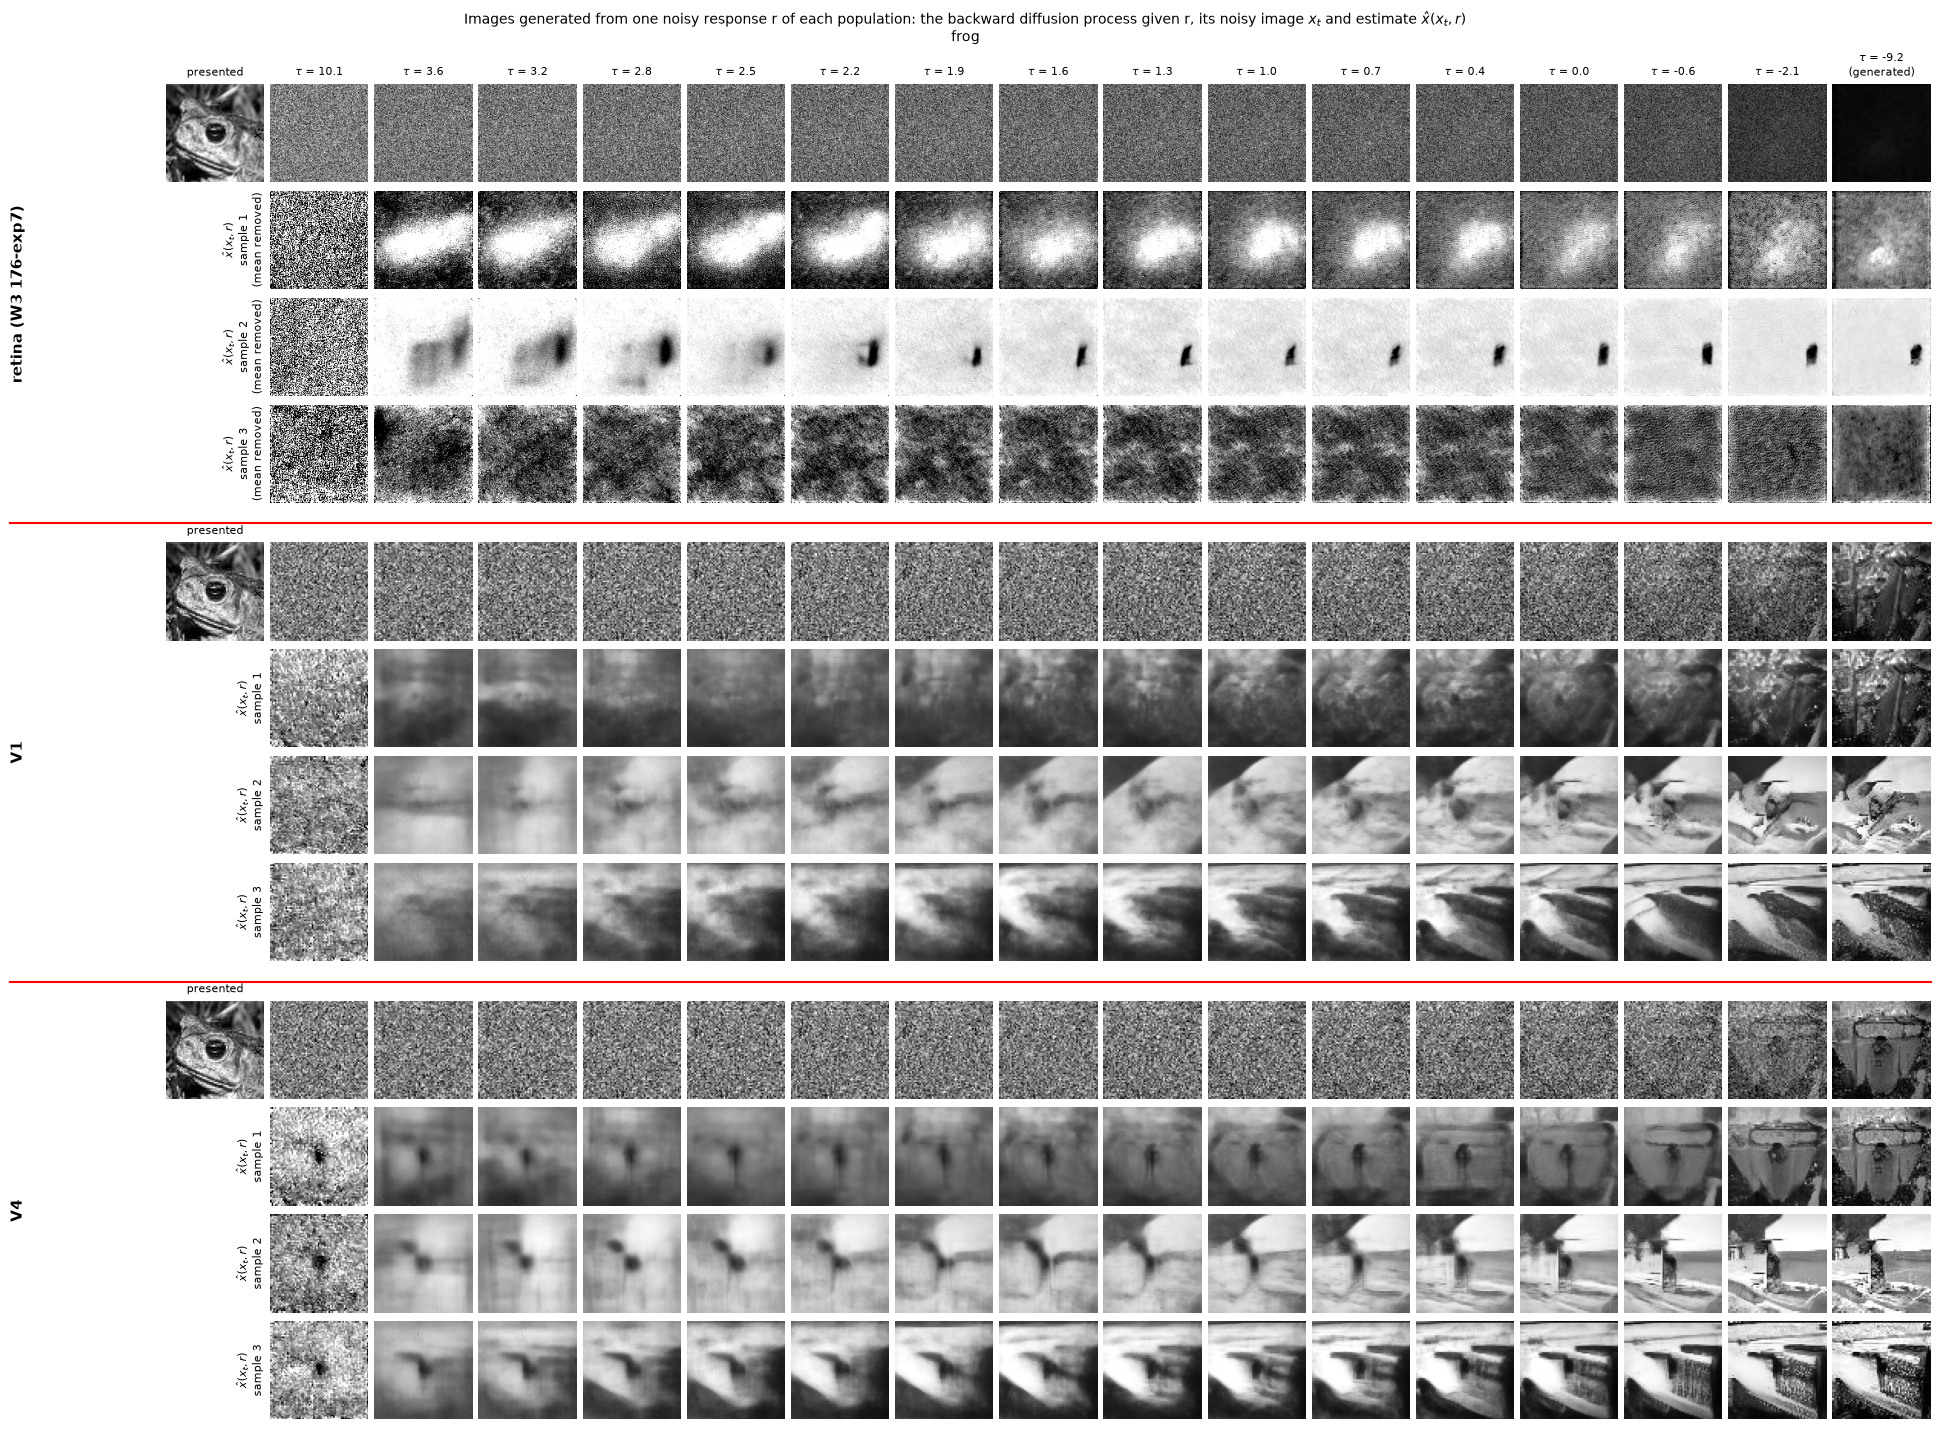

In [5]:
%%time

figure_dir = Path(PARAMS["figure_dir"])
figure_dir.mkdir(parents=True, exist_ok=True)
title = (
    "Images generated from one noisy response r of each population: the backward"
    r" diffusion process given r, its noisy image $x_t$ and estimate $\hat x(x_t, r)$"
)
for i, name in enumerate(names):
    blocks = {
        population: (
            images[i : i + 1],
            {s: (x_t[i], x_hat[i]) for s, (x_t, x_hat) in trajectory.items()},
        )
        for population, (images, trajectory) in results.items()
    }
    fig, _ = plot_posterior_samples(blocks, PARAMS, f"{title}\n{name}")
    fig.savefig(
        figure_dir / f"posterior_samples_{name}.png",
        dpi=PARAMS["file_dpi"],
        bbox_inches="tight",
    )
    if name not in PARAMS["show"]:
        plt.close(fig)
print(len(names), "figures saved in", figure_dir)

## 5. Conclusion

(written after the run)